In [1]:
from jhr.codes.espresso.io import QEOutParser
prs = QEOutParser('pw.x')
file = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/study/scf.out'
file = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/linking/relax.out'
df = prs.outparser.Process(file)

/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/linking/relax.out


In [14]:
import numpy as np
ucs = -126/2
ui = -757/2
upb = -3482/4
uzn = -923

u = np.array([ucs, upb, ui])
n = np.array([8, 8, 24])

e_bulk = -16564

(e_bulk - np.sum(u*n))/np.sum(n)*13.6



np.float64(-4.08)

## Defect Analysis (Test)

In [18]:
if True:
    import sys
    sys.path.append("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/")
    # ------------------------
    
    import warnings
    from monty.serialization import loadfn
    # from pymatgen.analysis.defects.thermo import FormationEnergyDiagram
    from jhr.dev.defect.thermo import FormationEnergyDiagram
    from pymatgen.io.vasp import Vasprun
    
    warnings.filterwarnings("ignore")
    
    from pathlib import Path
    
    from pymatgen.analysis.defects.core import Substitution
    from pymatgen.core import PeriodicSite, Species, Structure
    
    directory = "/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/tests/test_files"
    #directory = "/home/fes33/Documents/Temp/Mg_Ga"
    
    TEST_FILES = Path(directory)


In [ ]:

gan_struct = Structure.from_file(TEST_FILES / "GaN.vasp")

# make a substitution site
ga_site = gan_struct[0]
mg_site = PeriodicSite(
    species=Species("Mg"), coords=ga_site.frac_coords, lattice=gan_struct.lattice
)

# instantiate the defect object
mg_ga = Substitution(structure=gan_struct, site=mg_site)

sc_dir = TEST_FILES / "Mg_Ga"
# ents = MPRester().get_entries_in_chemsys("Mg-Ga-N") # Query from MPRester
ents = loadfn(TEST_FILES / "Ga_Mg_N.json")  # Load from local

print(ents)
print("----")

fed = FormationEnergyDiagram.with_directories(
    directory_map={
        "bulk": sc_dir / "bulk_sc",
        0: sc_dir / "q=0",
        # -1: sc_dir / "q=-1",
        # 1: sc_dir / "q=1",
    },
    defect=mg_ga,
    pd_entries=ents,
    dielectric=10,
)

fed.as_dataframe()

In [ ]:


from pymatgen.analysis.defects.corrections.freysoldt import plot_plnr_avg
plot_data = fed.defect_entries[1].corrections_metadata["freysoldt"]["plot_data"]
plot_plnr_avg(plot_data[0], title="Lattice Direction 1")
plot_plnr_avg(plot_data[1], title="Lattice Direction 2")
plot_plnr_avg(plot_data[2], title="Lattice Direction 3")



## Defect Analysis

In [1]:
if 'imports':
    apikey = '4a3cEY6Q0G6DyR1BcQQ8UaDGK4JO3KFU'
    import sys
    import json
    #sys.path.append("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/")
    sys.path.append("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Cloned/pymatgen-analysis-defects")
    # ------------------------
    from pymatgen.core import Element
    from mp_api.client import MPRester
    from pymatgen.io.espresso.outputs import PWxml
    
    
    import warnings
    from monty.serialization import loadfn, dumpfn
    # from pymatgen.analysis.defects.thermo import FormationEnergyDiagram
    from jhr.dev.defect.thermo import FormationEnergyDiagram
    from pymatgen.io.vasp import Vasprun
    
    warnings.filterwarnings("ignore")
    
    from pathlib import Path
    
    from pymatgen.analysis.defects.core import Substitution
    from pymatgen.core import PeriodicSite, Species, Structure
    
    #directory = "/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/tests/test_files"
    directory = "/home/fes33/Documents/Temp/"
    
    TEST_FILES = Path(directory)

pristine_file = '/home/fes33/Documents/Temp/Mg_Ga/bulk_sc/aiida.xml'
pristine_calc = PWxml(pristine_file)

pristine_struct = pristine_calc.structures[0]
site_num = 8

# make a substitution site
defect_site = pristine_struct[site_num]
defect_periodic = PeriodicSite(
    species=Species("Zn"), 
    coords=defect_site.frac_coords, 
    lattice=pristine_struct.lattice
)

# instantiate the defect object
defect = Substitution(structure=pristine_struct, site=defect_periodic)


sc_dir = TEST_FILES / "Mg_Ga"

download = True
if download: 
    with MPRester(apikey) as mpr:
        ents = mpr.get_entries_in_chemsys("Cs-Pb-I") # Query from MPRester
        dumpfn(ents, "ents.json", indent=2) 
else:
    ents = loadfn('ents.json')
    
fed = FormationEnergyDiagram.with_directoriesQE(
    directory_map={
        "bulk": sc_dir / "bulk_sc",
        # 0: sc_dir / "q=0",
        # -1: sc_dir / "q=-1",
        1: sc_dir / "q=1",
    },
    defect=defect,
    pd_entries=ents,
    dielectric=25,
    vbm = 0.3,
    bulk_stability = 0,
    standardize = 'pbe'
)


/home/fes33/miniforge3/envs/py313mats/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Retrieving ThermoDoc documents: 100%|███████| 58/58 [00:00<00:00, 914547.49it/s]


ENTRY 1


In [22]:
len(fed.defect_entries)

1

In [ ]:
dir(fed)

In [28]:
len(fed.pd_entries)

58

In [26]:
fed.competing_phases[0]['PbI2']

PDEntry : Pb4 I8 with energy = -14.0850

<Axes: title={'center': 'Lattice Direction 3'}, xlabel='distance along axis ($\\AA$)', ylabel='Potential (V)'>

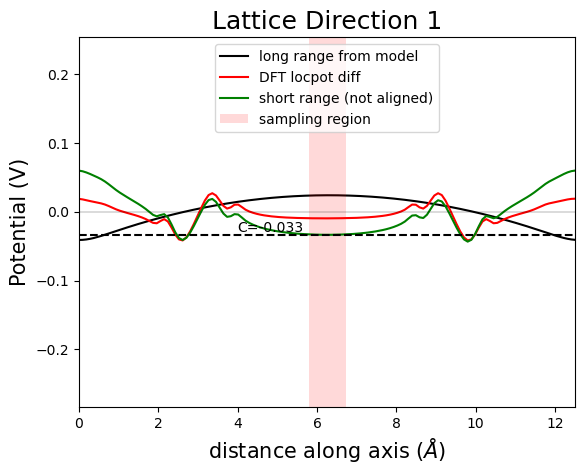

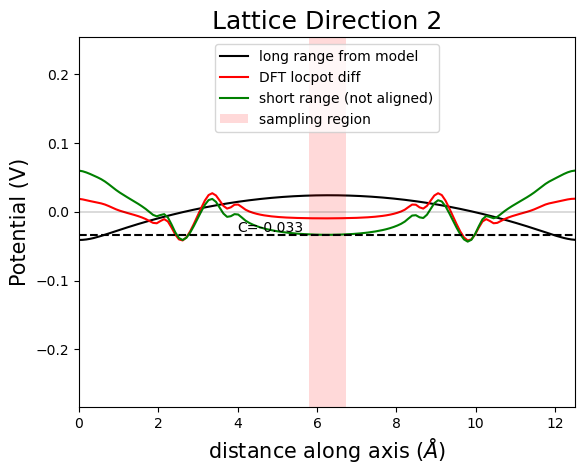

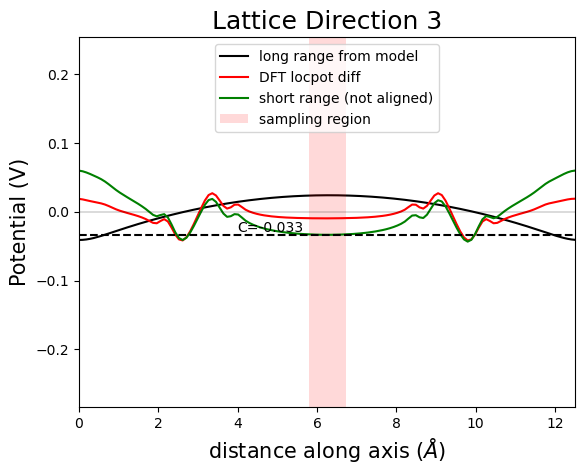

In [3]:


from pymatgen.analysis.defects.corrections.freysoldt import plot_plnr_avg
plot_data = fed.defect_entries[0].corrections_metadata["freysoldt"]["plot_data"]
plot_plnr_avg(plot_data[0], title="Lattice Direction 1")
plot_plnr_avg(plot_data[1], title="Lattice Direction 2")
plot_plnr_avg(plot_data[2], title="Lattice Direction 3")

## class

In [138]:
from jhr._helpers import Constants
class PWParse:
    """
    From: https://blog.levilentz.com/parse-quantum-espresso-output-file/

    Takes a pw.x output file and reads all the relevant values.

    Example:
      test = PWParse()
      test.Process("vc.out")

      print(test.to_JSON())


    """


    def __init__(self, file = None):
        self.file = file
        self.BOHRtoA = Constants.BOHRtoA
        self.RYtoeV = Constants.RYtoeV
    def Process(self, file_path = None):
        """
        Parses a passed file for standard parsing. Uses self.file if no file is passed. 
        """
        if file_path is None: file_path = self.file

        cols = ["value", "unit", "description"]
        self.data = pd.DataFrame(columns=cols)
        self.lattice = {"a": [0, 0, 0], "b": [0, 0, 0], "c": [0, 0, 0]}
        self.norms = {}
        self.angles = {}
        self.atoms = []
        
        print(file_path)
        f = open(file_path, "r")

        for linenum, i in enumerate(f):
            if linenum < 1000:
                if "number of k points=" in i:
                    val = 8
                    self.data.loc["kpoints"] = [val, "unitless", "Number of k-points in the Brillouin zone"]
                    continue
            if "End of self-consistent calculation" in i:
                bands = 8
                kpts = 74
                
                numlines = int(np.floor(bands / 8.0)) + 1

                bnddiagram = np.zeros((kpts, bands),dtype=float)
                counter = 0
                while counter < kpts:
                    line = next(f)
                    if "k =" in line:
                        line = next(f)
                        idx = 0
                        for _ in range(numlines):
                            line = next(f).split()
                            for val in line:
                                bnddiagram[counter][idx] = float(val)
                                idx += 1
                        counter += 1
                bnddiagram = np.random.rand(74,
                self.data.loc["bnddiagram"] = [bnddiagram, "N/A", "Band diagram"]
                continue

        f.close()
        return self.data


## doped

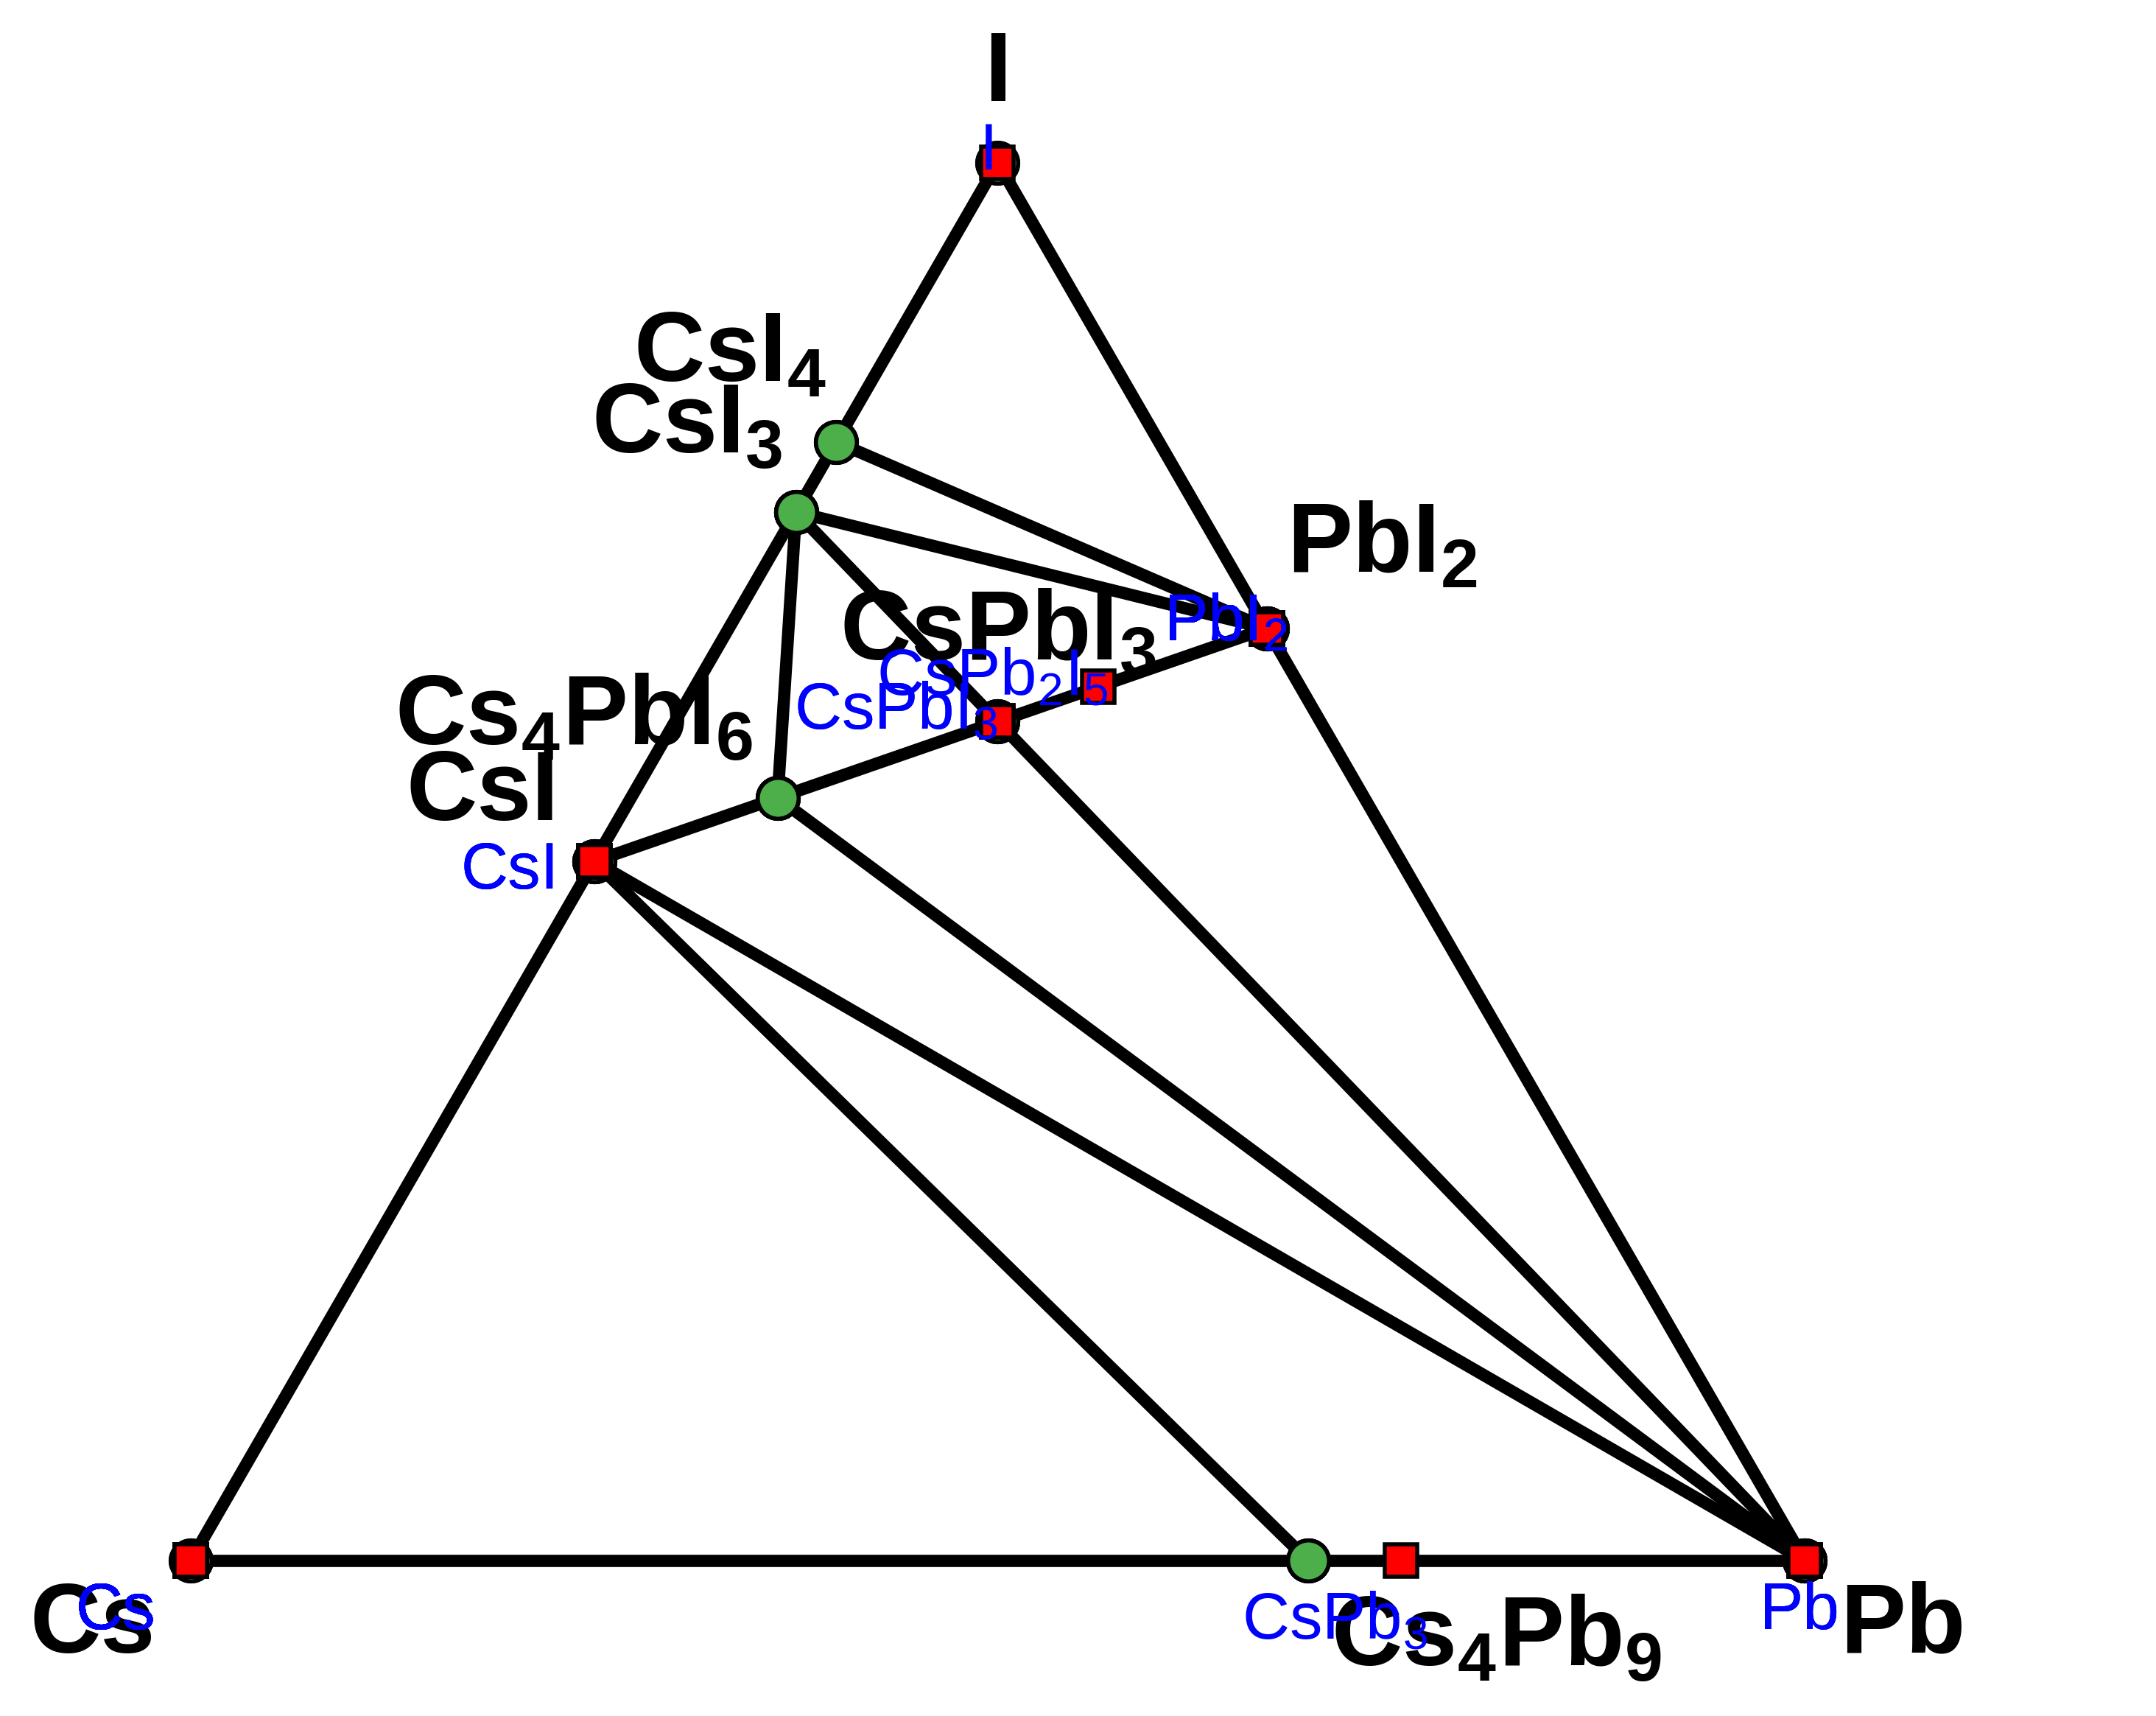

In [29]:
import doped
import matplotlib.pyplot as plt

plt.rcdefaults()
plt.style.use(f"{doped.__path__[0]}/utils/doped.mplstyle")  # use doped style
from pymatgen.ext.matproj import MPRester
from pymatgen.analysis.phase_diagram import PhaseDiagram, PDPlotter

# system = ["Cs", "Pb", "I"]  # system we want to get phase diagram for
# mpr = MPRester(apikey)  # object for connecting to MP Rest interface, may need to specify API key here
# entries = mpr.get_entries_in_chemsys(system)  # get all entries in the chemical system

#---> entries
pd = PhaseDiagram(entries)  # create phase diagram object
plotter = PDPlotter(pd, show_unstable=0.1, backend="matplotlib")  # plot phase diagram
plot = plotter.get_plot()